In [6]:
from pathlib import Path

import torch
import torch.nn as nn
import torch.optim as optim
import xgboost as xgb
import numpy as np
import utils
import seaborn as sns


from utils import (
    calculate_technical_indicators,
    compare_results,
    evaluate_predictions,
    evaluate_torch_model,
    fit_arima,
    fit_standard_scaler,
    forecast_arima,
    grid_search_arima,
    load_fred_data,
    normalize_to_tensor,
    plot_dataset,
    plot_predictions_vs_targets,
    predict_and_store_log_return_model,
    predict_moving_average,
    predict_naive,
    prepare_data,
    split_data,
    store_model_prediction,
    train_torch_model,
    train_xgboost,
)

DATA_DIR = Path("FRED")
RESULTS_PATH = Path("model_results.json")
TARGET_COLUMN = "INR"
FEATURE_COLUMNS = ["JPY", "EUR", "FFER", "US10YY"]
TRAIN_FRACTION = 0.8
VALIDATION_FRACTION = 0.1
EPOCHS = 100
BATCH_SIZE = 32
model_results = {}

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print(f"Using device: {DEVICE}")

Using device: cuda


In [7]:
full_df = prepare_data(load_fred_data(DATA_DIR))
full_df["TARGET_NEXT"] = full_df[TARGET_COLUMN].shift(-1)
full_df = full_df.dropna(subset=["TARGET_NEXT"])

train_df, val_df, test_df = split_data(
    full_df,
    train_fraction=TRAIN_FRACTION,
    validation_fraction=VALIDATION_FRACTION,
)

full_df.head()

,INR,JPY,EUR,FFER,US10YY,TARGET_NEXT
observation_date,,,,,,
1999-01-04,42.60,112.15,1.1812,5.04,4.69,42.56
1999-01-05,42.56,111.15,1.1760,4.54,4.74,42.55
1999-01-06,42.55,112.78,1.1636,4.23,4.73,42.55
1999-01-07,42.55,111.69,1.1672,4.49,4.77,42.55
1999-01-08,42.55,111.52,1.1554,4.74,4.86,42.55


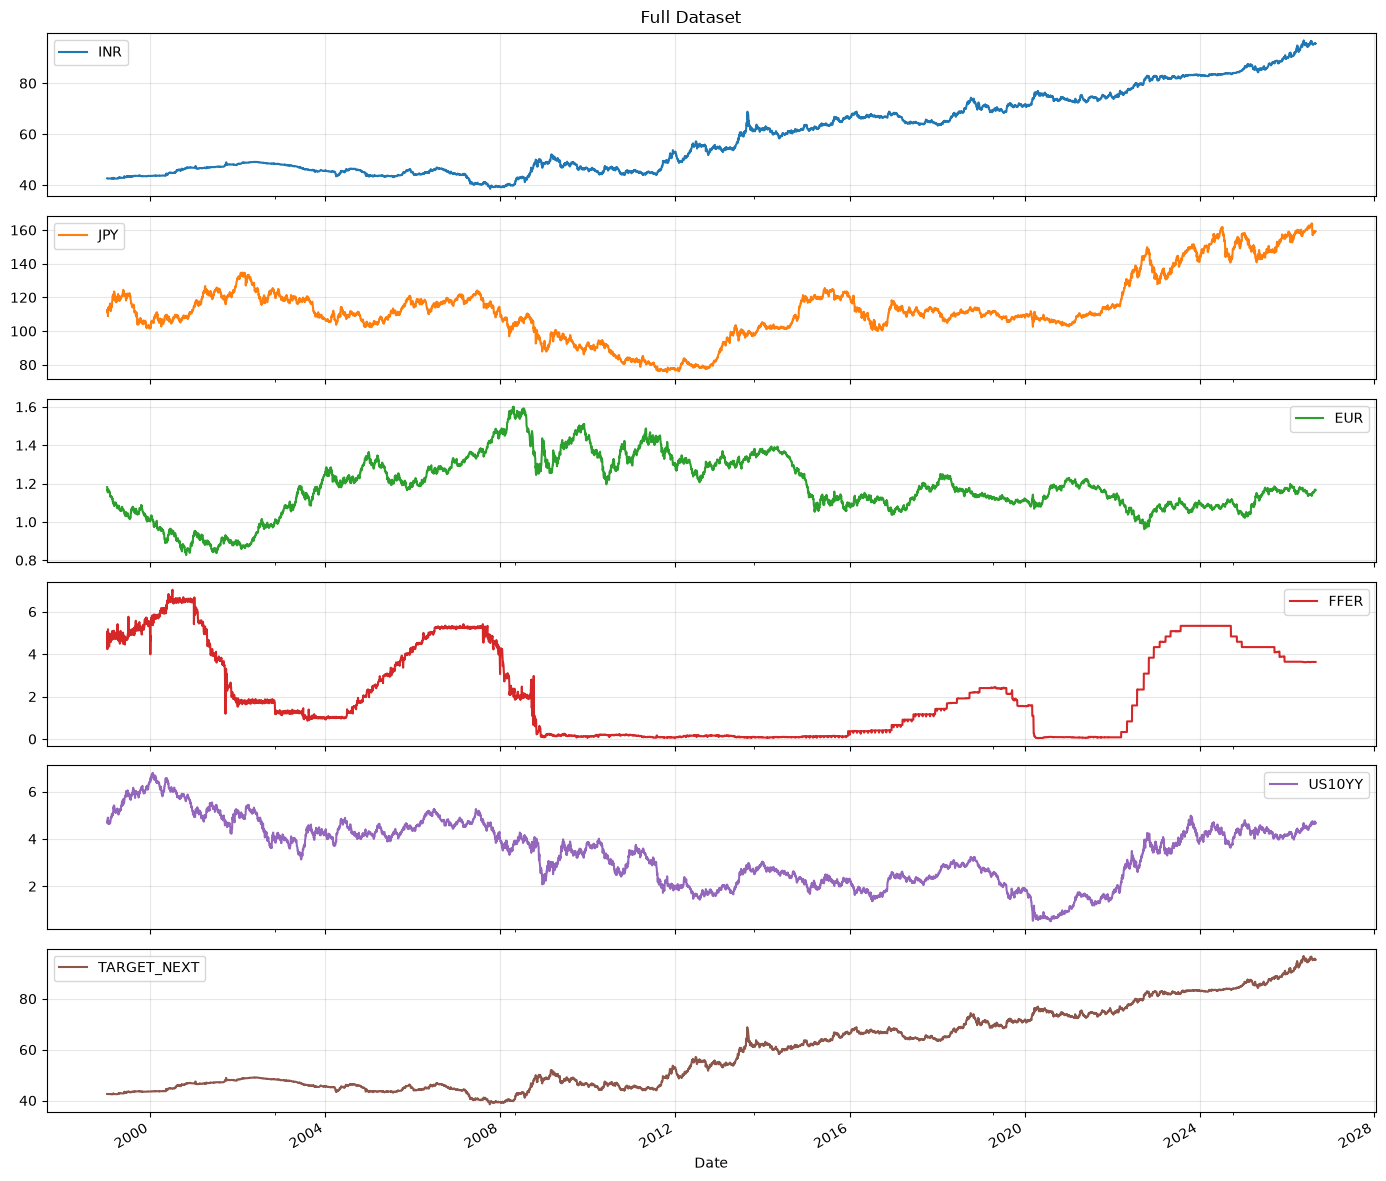

Train: (5524, 6), validation: (690, 6), test: (691, 6)


In [8]:
plot_dataset(full_df)
print(f"Train: {train_df.shape}, validation: {val_df.shape}, test: {test_df.shape}")

## Baseline and ARIMA

Naive: {'mae': 0.1493805826271353, 'mse': 0.07776622105608079, 'rmse': 0.27886595535504294, 'directional_accuracy': 53.08709034944776, 'correct_days': 2932, 'total_days': 5523}
Moving average: {'mae': 0.11185312760039676, 'mse': 0.07249965294511787, 'rmse': 0.2692575958912169, 'directional_accuracy': 78.20025348542458, 'correct_days': 4319, 'total_days': 5523}


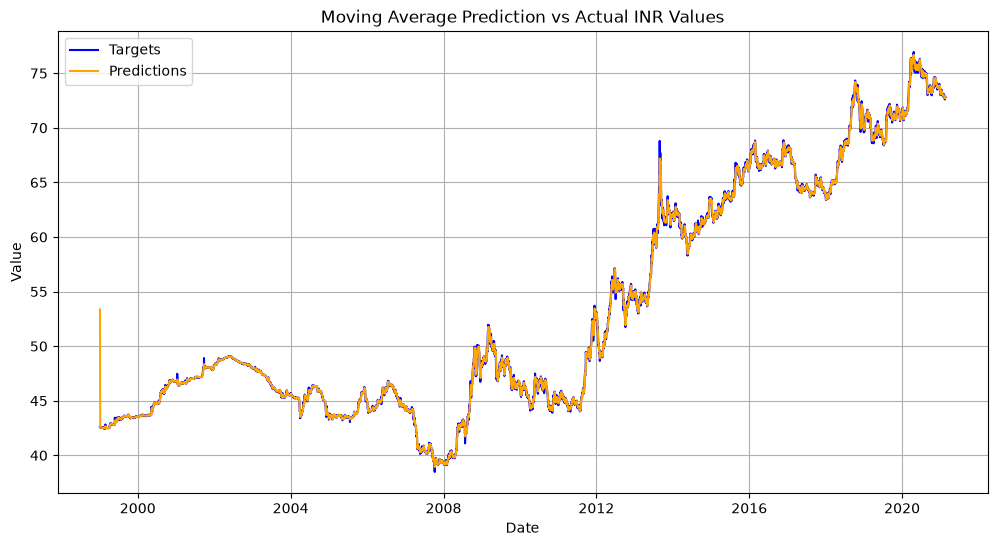

In [4]:
naive_predictions = predict_naive(train_df, TARGET_COLUMN)
moving_average_predictions = predict_moving_average(train_df, target_column=TARGET_COLUMN)

naive_metrics = evaluate_predictions(naive_predictions, train_df[TARGET_COLUMN])
moving_average_metrics = evaluate_predictions(
    moving_average_predictions,
    train_df[TARGET_COLUMN],
)
store_model_prediction(
    model_results,
    "Naive",
    naive_predictions,
    naive_metrics,
    "train",
)
store_model_prediction(
    model_results,
    "Moving Average",
    moving_average_predictions,
    moving_average_metrics,
    "train",
)
print("Naive:", naive_metrics)
print("Moving average:", moving_average_metrics)
plot_predictions_vs_targets(
    moving_average_predictions,
    train_df[TARGET_COLUMN],
    x_values=train_df.index,
    title="Moving Average Prediction vs Actual INR Values",
)

/media/prince/167GB/AIML/.venv/lib/python3.13/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/media/prince/167GB/AIML/.venv/lib/python3.13/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/media/prince/167GB/AIML/.venv/lib/python3.13/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/media/prince/167GB/AIML/.venv/lib/python3.13/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/media/prince/167GB/AIML/.venv/lib/python3.13/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maxi

        order       mae          aic
13  (2, 0, 1)  1.205977  1119.841793
7   (1, 0, 1)  3.186553   969.581745
12  (2, 0, 0)  3.973017   983.011763
8   (1, 0, 2)  4.847509  1019.785826
14  (2, 0, 2)  5.150125  1196.039656
Best ARIMA order: (2, 0, 1)


/media/prince/167GB/AIML/.venv/lib/python3.13/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


{'mae': 1.205977239748999, 'mse': 2.5201668038105103, 'rmse': 1.5875033240313263, 'directional_accuracy': 53.12046444121916, 'correct_days': 366, 'total_days': 689}


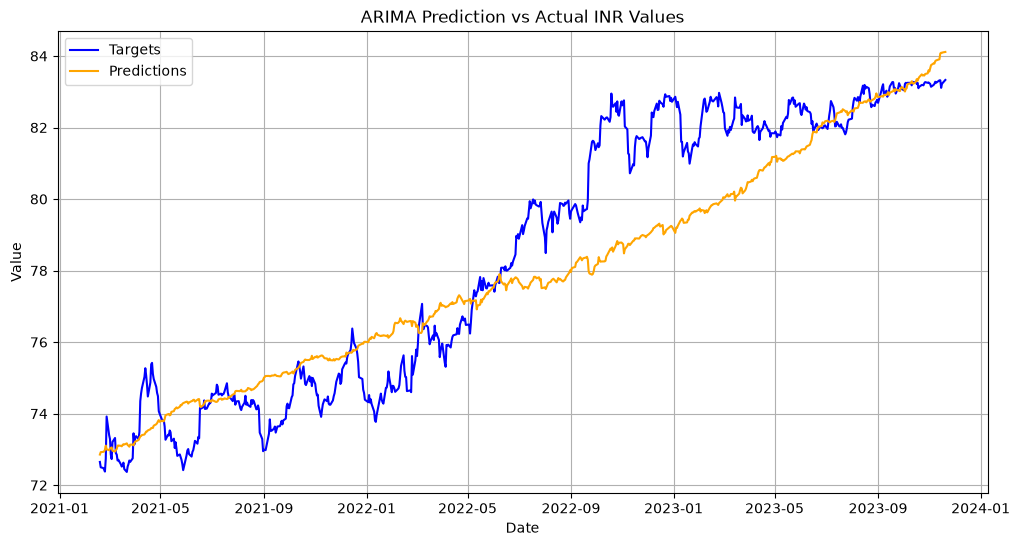

In [5]:
search_results, best_order = grid_search_arima(
    train_df,
    val_df,
    FEATURE_COLUMNS,
    p_values=range(0, 3),
    d_values=range(0, 2),
    q_values=range(0, 3),
    target_column=TARGET_COLUMN,
)
print(search_results.head())
print(f"Best ARIMA order: {best_order}")
arima_model = fit_arima(train_df, FEATURE_COLUMNS, best_order, TARGET_COLUMN)
arima_train_predictions = arima_model.predict(
    start=0,
    end=len(train_df) - 1,
    exog=train_df[FEATURE_COLUMNS],
)
arima_predictions, arima_metrics = forecast_arima(
    arima_model,
    val_df,
    FEATURE_COLUMNS,
    TARGET_COLUMN,
)
arima_train_metrics = evaluate_predictions(
    arima_train_predictions,
    train_df[TARGET_COLUMN],
)
store_model_prediction(
    model_results,
    "ARIMA",
    arima_train_predictions,
    arima_train_metrics,
    "train",
)
store_model_prediction(
    model_results,
    "ARIMA",
    arima_predictions,
    arima_metrics,
    "validation",
)
print(arima_metrics)
plot_predictions_vs_targets(
    arima_predictions,
    val_df[TARGET_COLUMN],
    x_values=val_df.index,
    title="ARIMA Prediction vs Actual INR Values",
)

## XGBoost

[0]	validation_0-rmse:10.25372	validation_1-rmse:25.29351	validation_2-rmse:34.48110
[100]	validation_0-rmse:1.07601	validation_1-rmse:26.19632	validation_2-rmse:43.18526
[200]	validation_0-rmse:0.70740	validation_1-rmse:26.17821	validation_2-rmse:43.63768
[300]	validation_0-rmse:0.61798	validation_1-rmse:26.15898	validation_2-rmse:43.68659
[400]	validation_0-rmse:0.55267	validation_1-rmse:26.14245	validation_2-rmse:43.69870
[499]	validation_0-rmse:0.50368	validation_1-rmse:26.11360	validation_2-rmse:43.67179
{'mae': 43.520977324997816, 'mse': 1907.2248406795463, 'rmse': 43.67178540750935, 'directional_accuracy': 44.927536231884055, 'correct_days': 310, 'total_days': 690}


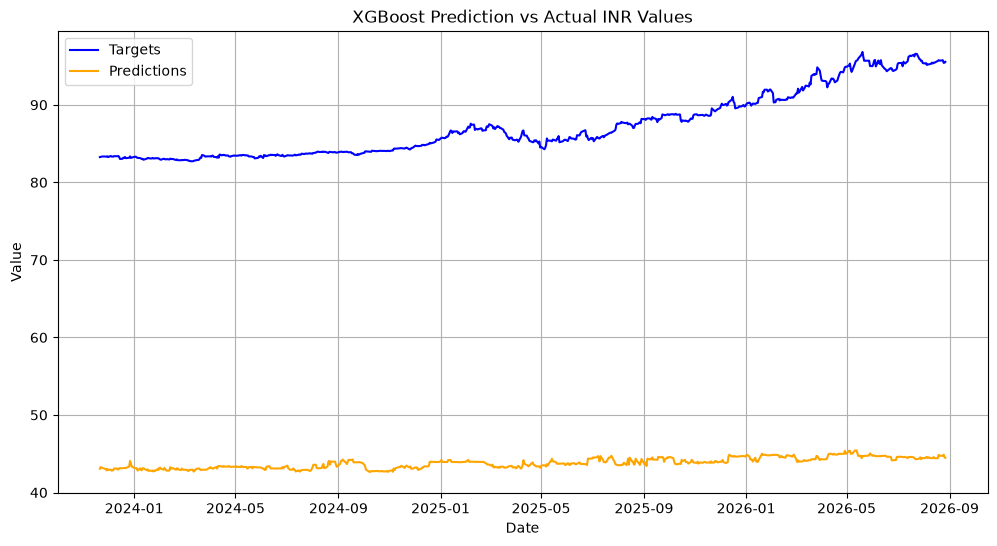

In [11]:
xgb_model = xgb.XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
)
xgb_model = train_xgboost(
    xgb_model,
    train_df,
    val_df,
    test_df,
    FEATURE_COLUMNS,
    TARGET_COLUMN,
)
xgb_train_predictions = xgb_model.predict(train_df[FEATURE_COLUMNS])
xgb_test_predictions = xgb_model.predict(test_df[FEATURE_COLUMNS])
xgb_train_metrics = evaluate_predictions(
    xgb_train_predictions,
    train_df[TARGET_COLUMN],
)
xgb_metrics = evaluate_predictions(
    xgb_test_predictions,
    test_df[TARGET_COLUMN],
)
store_model_prediction(
    model_results,
    "XGBoost",
    xgb_train_predictions,
    xgb_train_metrics,
    "train",
)
store_model_prediction(
    model_results,
    "XGBoost",
    xgb_test_predictions,
    xgb_metrics,
    "test",
)
print(xgb_metrics)
plot_predictions_vs_targets(
    xgb_test_predictions,
    test_df[TARGET_COLUMN],
    x_values=test_df.index,
    title="XGBoost Prediction vs Actual INR Values",
)

In [12]:
baseline_feature_columns = FEATURE_COLUMNS + [TARGET_COLUMN]
X_train = torch.tensor(
    train_df[baseline_feature_columns].values,
    dtype=torch.float32,
)
y_train = torch.tensor(
    train_df[TARGET_COLUMN].shift(-1).interpolate(limit_direction="both").values,
    dtype=torch.float32,
).view(-1, 1)
X_val = torch.tensor(
    val_df[baseline_feature_columns].values,
    dtype=torch.float32,
)
y_val = torch.tensor(
    val_df[TARGET_COLUMN].shift(-1).interpolate(limit_direction="both").values,
    dtype=torch.float32,
).view(-1, 1)
X_test = torch.tensor(
    test_df[baseline_feature_columns].values,
    dtype=torch.float32,
)
y_test = torch.tensor(
    test_df[TARGET_COLUMN].shift(-1).interpolate(limit_direction="both").values,
    dtype=torch.float32,
).view(-1, 1)

NUM_INPUT_FEATURES = X_train.shape[1]
OUTPUT_FEATURES = 1

linear_model = nn.Linear(NUM_INPUT_FEATURES, OUTPUT_FEATURES)
linear_optimizer = optim.Adam(linear_model.parameters(), lr=0.01)
linear_losses = train_torch_model(
    linear_model,
    linear_optimizer,
    nn.MSELoss(),
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=EPOCHS,
)

deep_model = nn.Sequential(
    nn.Linear(NUM_INPUT_FEATURES, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, OUTPUT_FEATURES),
)
deep_optimizer = optim.Adam(deep_model.parameters(), lr=0.01)
deep_losses = train_torch_model(
    deep_model,
    deep_optimizer,
    nn.MSELoss(),
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=EPOCHS,
)

with torch.no_grad():
    linear_train_predictions = linear_model(X_train)
    linear_test_predictions = linear_model(X_test)
    deep_train_predictions = deep_model(X_train)
    deep_test_predictions = deep_model(X_test)

linear_train_metrics = evaluate_predictions(linear_train_predictions, y_train)
linear_metrics = evaluate_predictions(linear_test_predictions, y_test)
deep_train_metrics = evaluate_predictions(deep_train_predictions, y_train)
deep_metrics = evaluate_predictions(deep_test_predictions, y_test)

store_model_prediction(
    model_results,
    "Linear Regression",
    linear_train_predictions,
    linear_train_metrics,
    "train",
)
store_model_prediction(
    model_results,
    "Linear Regression",
    linear_test_predictions,
    linear_metrics,
    "test",
)
store_model_prediction(
    model_results,
    "Deep Learning",
    deep_train_predictions,
    deep_train_metrics,
    "train",
)
store_model_prediction(
    model_results,
    "Deep Learning",
    deep_test_predictions,
    deep_metrics,
    "test",
)

print(f"Linear Regression test metrics: {linear_metrics}")
print(f"Deep Learning test metrics: {deep_metrics}")

Epoch 10/100, Train Loss: 1602.8573, Val Loss: 3203.8853
Epoch 20/100, Train Loss: 622.2835, Val Loss: 1387.6509
Epoch 30/100, Train Loss: 175.0778, Val Loss: 468.8688
Epoch 40/100, Train Loss: 54.6469, Val Loss: 129.8278
Epoch 50/100, Train Loss: 49.6208, Val Loss: 44.2072
Epoch 60/100, Train Loss: 52.4481, Val Loss: 33.4195
Epoch 70/100, Train Loss: 47.4978, Val Loss: 45.0946
Epoch 80/100, Train Loss: 43.2743, Val Loss: 63.4837
Epoch 90/100, Train Loss: 41.4840, Val Loss: 75.7643
Epoch 100/100, Train Loss: 40.1637, Val Loss: 77.5020
Epoch 10/100, Train Loss: 99.5956, Val Loss: 415.1790
Epoch 20/100, Train Loss: 76.9493, Val Loss: 27.2687
Epoch 30/100, Train Loss: 76.2030, Val Loss: 259.9996
Epoch 40/100, Train Loss: 49.7142, Val Loss: 12.5530
Epoch 50/100, Train Loss: 19.7147, Val Loss: 33.3751
Epoch 60/100, Train Loss: 9.3700, Val Loss: 31.8059
Epoch 70/100, Train Loss: 3.0915, Val Loss: 9.6804
Epoch 80/100, Train Loss: 2.3611, Val Loss: 3.9621
Epoch 90/100, Train Loss: 2.1631, Val 

## Technical indicators

In [13]:
technical_data = calculate_technical_indicators(full_df).dropna()
technical_data["TARGET_NEXT"] = technical_data["Log_Returns"].shift(-1)
technical_data = technical_data.dropna(subset=["TARGET_NEXT"])
technical_data.head()

,INR,JPY,EUR,FFER,US10YY,TARGET_NEXT,MA_5,MA_10,MA_30,MA_50,...,EMA_50,EMA_100,RSI,BB_Middle,BB_Upper,BB_Lower,Volatility,ATR_14_proxy,ATR_%_proxy,Log_Returns
observation_date,,,,,,,,,,,,,,,,,,,,,
1999-05-25,42.80,122.88,1.0587,4.80,5.49,0.003499,42.800,42.796,42.831000,42.7324,...,42.748324,42.686452,50.000000,42.8105,42.873571,42.747429,0.031535,0.010000,0.023364,0.000000
1999-05-26,42.95,122.03,1.0471,4.81,5.55,0.011574,42.830,42.811,42.834333,42.7414,...,42.756233,42.691671,75.862069,42.8130,42.892763,42.733237,0.039881,0.020714,0.048229,0.003499
1999-05-27,43.45,121.27,1.0439,4.87,5.62,-0.006465,42.960,42.876,42.852667,42.7604,...,42.783440,42.706688,91.139241,42.8425,43.138571,42.546429,0.148035,0.056429,0.129870,0.011574
1999-05-28,43.17,120.88,1.0422,4.61,5.64,-0.003946,43.034,42.910,42.866667,42.7738,...,42.798599,42.715862,67.289720,42.8590,43.189289,42.528711,0.165144,0.076429,0.177041,-0.006465
1999-06-01,43.00,120.75,1.0449,4.78,5.78,0.000000,43.074,42.934,42.868333,42.7838,...,42.806497,42.721489,58.064516,42.8665,43.202688,42.530312,0.168094,0.088571,0.205980,-0.003946


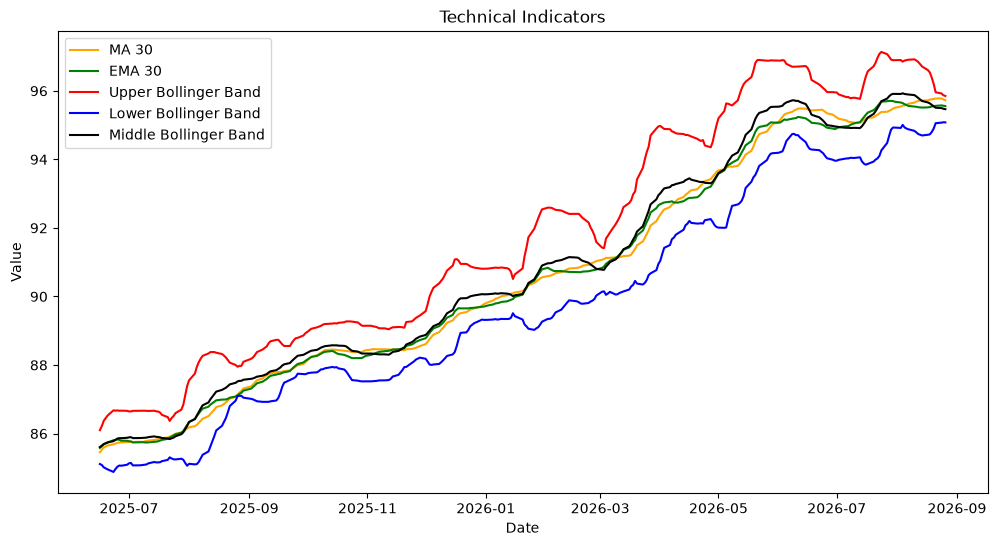

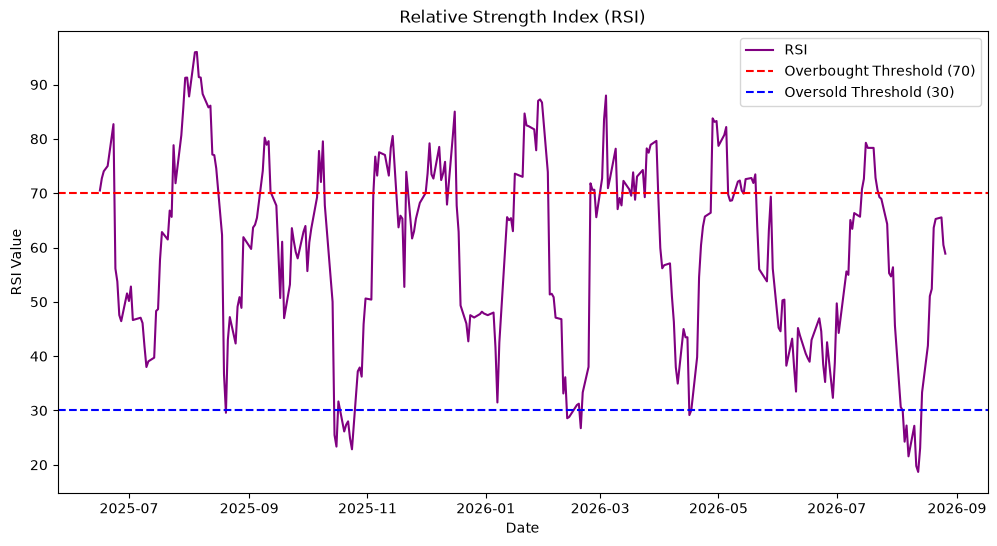

In [14]:
# Plot data with technical indicators - MA30, EMA30, RSI, bollinger bands
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(technical_data[-300:].index, technical_data[-300:]["MA_30"], label="MA 30", color="orange")
plt.plot(technical_data[-300:].index, technical_data[-300:]["EMA_30"], label="EMA 30", color="green")
plt.plot(technical_data[-300:].index, technical_data[-300:]["BB_Upper"], label="Upper Bollinger Band", color="red")
plt.plot(technical_data[-300:].index, technical_data[-300:]["BB_Lower"], label="Lower Bollinger Band", color="blue")
plt.plot(technical_data[-300:].index, technical_data[-300:]["BB_Middle"], label="Middle Bollinger Band", color="black")
plt.title("Technical Indicators")
plt.xlabel("Date")
plt.ylabel("Value")
plt.legend()
plt.show()

## RSI
plt.figure(figsize=(12, 6))
plt.plot(technical_data[-300:].index, technical_data[-300:]["RSI"], label="RSI", color="purple")
plt.title("Relative Strength Index (RSI)")
plt.xlabel("Date")
plt.ylabel("RSI Value")
plt.axhline(70, color="red", linestyle="--", label="Overbought Threshold (70)")
plt.axhline(30, color="blue", linestyle="--", label="Oversold Threshold (30)")
plt.legend()
plt.show()

### Analysis of tecchnical data

<Axes: >

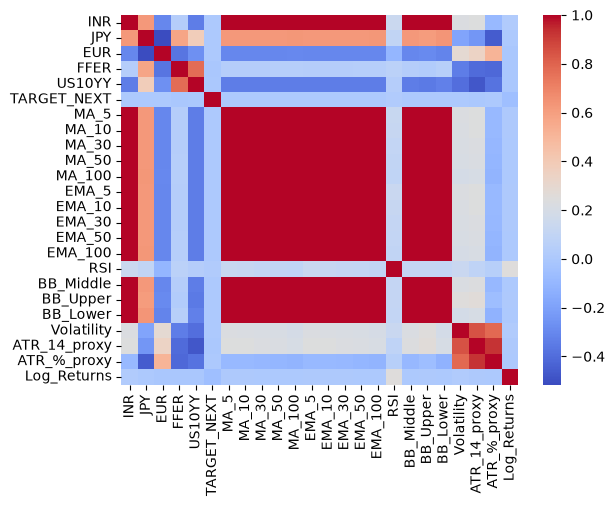

In [15]:
##  code to plot the technical indicators

sns.heatmap(technical_data.corr(), cmap="coolwarm")

In [16]:
NUM_INPUT_FEATURES = len(FEATURE_COLUMNS) + 1 + 12  # Original features + target + technical indicators
OUTPUT_FEATURES = 1  # Predicting the next price

train_df_ta, val_df_ta, test_df_ta = split_data(
    technical_data,
    train_fraction=TRAIN_FRACTION,
    validation_fraction=VALIDATION_FRACTION,
)

In [17]:
ta_columns = [
    "MA_5",
    "MA_10",
    "MA_30",
    "MA_50",
    "MA_100",
    "EMA_5",
    "EMA_10",
    "EMA_30",
    "EMA_50",
    "EMA_100",
    "RSI",
    "BB_Middle",
    "BB_Upper",
    "BB_Lower",
    "Volatility",
    "ATR_14_proxy",
    "ATR_%_proxy",
    "Log_Returns",
]

all_features = FEATURE_COLUMNS + [TARGET_COLUMN] + ta_columns

In [18]:
TARGET_COLUMN = "INR"
technical_target_column = "TARGET_NEXT"

In [19]:
feature_scaler = fit_standard_scaler(train_df_ta, all_features)

train_targets = train_df_ta["TARGET_NEXT"]
val_targets = val_df_ta["TARGET_NEXT"]
test_targets = test_df_ta["TARGET_NEXT"]
target_scaler = fit_standard_scaler(train_targets)

X_train = normalize_to_tensor(train_df_ta, feature_scaler, all_features)
X_val = normalize_to_tensor(val_df_ta, feature_scaler, all_features)
X_test = normalize_to_tensor(test_df_ta, feature_scaler, all_features)
y_train = normalize_to_tensor(train_targets, target_scaler)
y_val = normalize_to_tensor(val_targets, target_scaler)
y_test = normalize_to_tensor(test_targets, target_scaler)

NUM_INPUT_FEATURES = X_train.shape[1]
OUTPUT_FEATURES = 1

In [20]:
model_linear_ta = nn.Linear(NUM_INPUT_FEATURES, OUTPUT_FEATURES)
model_linear_ta_optimizer = optim.Adam(
    model_linear_ta.parameters(),
    lr=0.001,
)
model_linear_ta_loss_function = nn.MSELoss()

In [21]:
EPOCHS = 100

model_linear_ta_losses = train_torch_model(
    model_linear_ta,
    model_linear_ta_optimizer,
    model_linear_ta_loss_function,
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=EPOCHS,
)

Epoch 10/100, Train Loss: 1.6473, Val Loss: 4.3121
Epoch 20/100, Train Loss: 1.4349, Val Loss: 3.0424
Epoch 30/100, Train Loss: 1.2807, Val Loss: 2.0921
Epoch 40/100, Train Loss: 1.1774, Val Loss: 1.4310
Epoch 50/100, Train Loss: 1.1133, Val Loss: 1.0030
Epoch 60/100, Train Loss: 1.0758, Val Loss: 0.7442
Epoch 70/100, Train Loss: 1.0544, Val Loss: 0.5966
Epoch 80/100, Train Loss: 1.0419, Val Loss: 0.5157
Epoch 90/100, Train Loss: 1.0340, Val Loss: 0.4723
Epoch 100/100, Train Loss: 1.0284, Val Loss: 0.4486


Test MAE: 0.1979, Test MSE: 0.0710


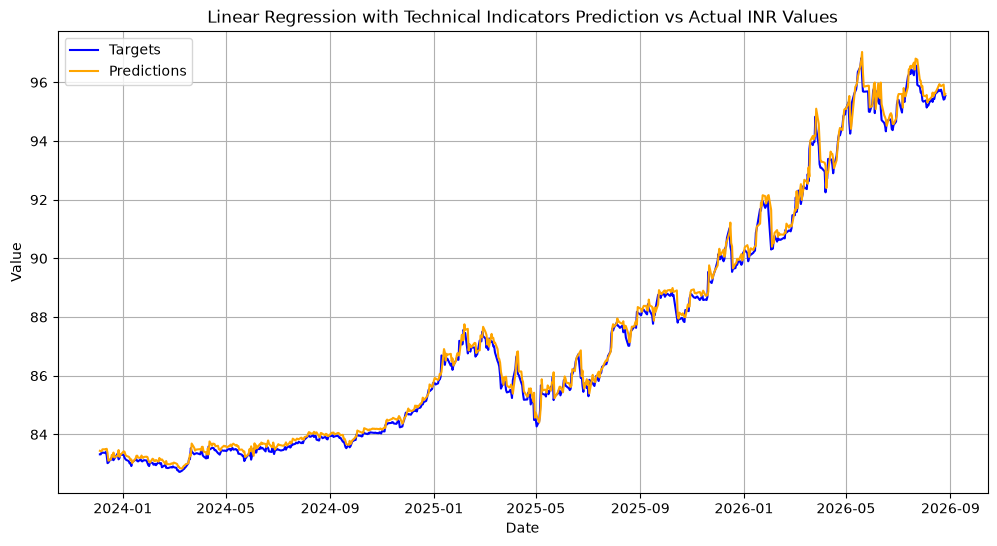

In [22]:
linear_ta_prediction_results = predict_and_store_log_return_model(
    model=model_linear_ta,
    model_name="Linear Regression with Technical Indicators",
    train_inputs=X_train,
    test_inputs=X_test,
    train_targets=y_train,
    test_targets=y_test,
    train_current_prices=train_df_ta["INR"].values,
    test_current_prices=test_df_ta["INR"].values,
    target_scaler=target_scaler,
    model_results=model_results,
    output_path=RESULTS_PATH,
)

predicted_train_prices_linear_ta = linear_ta_prediction_results["train_predictions"]
predicted_prices_linear_ta = linear_ta_prediction_results["test_predictions"]
actual_train_prices_ta = linear_ta_prediction_results["train_actual_prices"]
actual_prices_ta = linear_ta_prediction_results["test_actual_prices"]
linear_ta_train_metrics = linear_ta_prediction_results["train_metrics"]
linear_ta_metrics = linear_ta_prediction_results["test_metrics"]

print(
    f"Test MAE: {linear_ta_metrics['mae']:.4f}, "
    f"Test MSE: {linear_ta_metrics['mse']:.4f}"
)
plot_predictions_vs_targets(
    predicted_prices_linear_ta,
    actual_prices_ta,
    x_values=test_df_ta.index,
    title="Linear Regression with Technical Indicators Prediction vs Actual INR Values",
)

In [23]:
model_dl_ta = nn.Sequential(
    nn.Linear(NUM_INPUT_FEATURES, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
)
model_dl_ta_optimizer = optim.Adam(
    model_dl_ta.parameters(),
    lr=0.001,
)
model_dl_ta_loss_function = nn.MSELoss()

In [24]:
train_losses_dl_ta = train_torch_model(
    model_dl_ta,
    model_dl_ta_optimizer,
    model_dl_ta_loss_function,
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=EPOCHS,
)

Epoch 10/100, Train Loss: 0.9949, Val Loss: 0.4103
Epoch 20/100, Train Loss: 0.9890, Val Loss: 0.4105
Epoch 30/100, Train Loss: 0.9848, Val Loss: 0.4104
Epoch 40/100, Train Loss: 0.9814, Val Loss: 0.4108
Epoch 50/100, Train Loss: 0.9777, Val Loss: 0.4112
Epoch 60/100, Train Loss: 0.9737, Val Loss: 0.4136
Epoch 70/100, Train Loss: 0.9694, Val Loss: 0.4209
Epoch 80/100, Train Loss: 0.9646, Val Loss: 0.4285
Epoch 90/100, Train Loss: 0.9593, Val Loss: 0.4412
Epoch 100/100, Train Loss: 0.9536, Val Loss: 0.4476


Test MAE: 0.1998, Test MSE: 0.0680


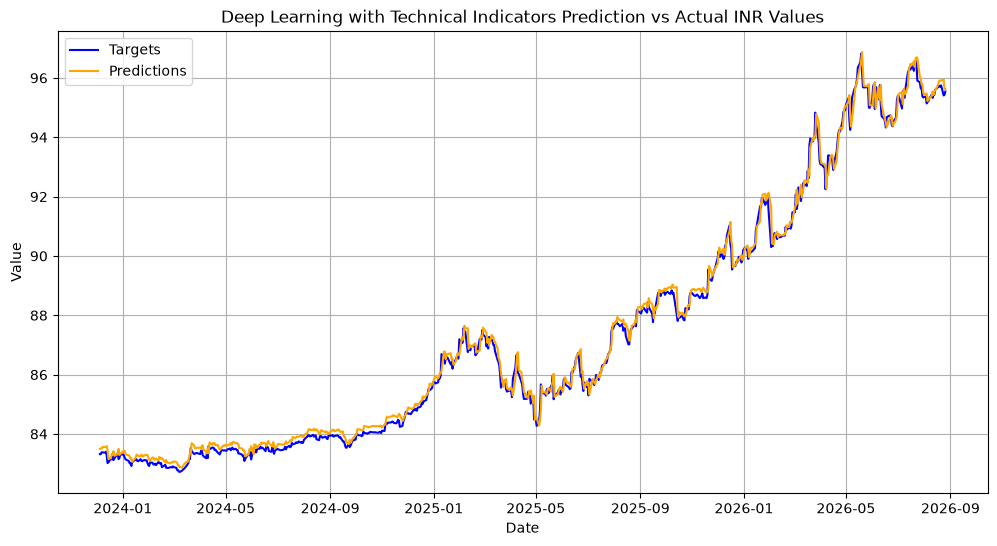

In [25]:
deep_ta_prediction_results = predict_and_store_log_return_model(
    model=model_dl_ta,
    model_name="Deep Learning with Technical Indicators",
    train_inputs=X_train,
    test_inputs=X_test,
    train_targets=y_train,
    test_targets=y_test,
    train_current_prices=train_df_ta["INR"].values,
    test_current_prices=test_df_ta["INR"].values,
    target_scaler=target_scaler,
    model_results=model_results,
    output_path=RESULTS_PATH,
)

predicted_train_prices_ta = deep_ta_prediction_results["train_predictions"]
predicted_prices_ta = deep_ta_prediction_results["test_predictions"]
actual_train_prices_ta = deep_ta_prediction_results["train_actual_prices"]
actual_prices_ta = deep_ta_prediction_results["test_actual_prices"]
deep_ta_train_metrics = deep_ta_prediction_results["train_metrics"]
deep_ta_metrics = deep_ta_prediction_results["test_metrics"]

print(
    f"Test MAE: {deep_ta_metrics['mae']:.4f}, "
    f"Test MSE: {deep_ta_metrics['mse']:.4f}"
)
plot_predictions_vs_targets(
    predicted_prices_ta,
    actual_prices_ta,
    x_values=test_df_ta.index,
    title="Deep Learning with Technical Indicators Prediction vs Actual INR Values",
)

## ADD NEW TEMPORAL FEATURES

In [26]:
TEMPORAL_FEATURES_NUMBER = 5  # Number of temporal features to include

In [27]:
import pandas as pd

def create_temporal_features(df, target_columns=None, num_features=5):
    """Add lagged temporal features"""
    df = df.copy()

    if target_columns is None:
        target_columns = [
            column for column in df.columns
            if column != "TARGET_NEXT"
        ]

    lagged_features = [
        df[target_columns]
        .shift(lag)
        .add_suffix(f"_lag_{lag}")
        for lag in range(1, num_features + 1)
    ]

    return pd.concat([df, *lagged_features], axis=1)


In [28]:
train_df_temp = create_temporal_features(
    train_df_ta.copy(),
    None,
    TEMPORAL_FEATURES_NUMBER,
).dropna()
val_df_temp = create_temporal_features(
    val_df_ta.copy(),
    None,
    TEMPORAL_FEATURES_NUMBER,
).dropna()
test_df_temp = create_temporal_features(
    test_df_ta.copy(),
    None,
    TEMPORAL_FEATURES_NUMBER,
).dropna()

In [29]:
train_df_temp.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 5439 entries, 1999-06-02 to 2021-03-16
Columns: 139 entries, INR to Log_Returns_lag_5
dtypes: float64(139)
memory usage: 5.8 MB


In [30]:
temporal_features = all_features + [
    f"{feature}_lag_{lag}"
    for feature in all_features
    for lag in range(1, TEMPORAL_FEATURES_NUMBER + 1)
]

feature_scaler_temp = fit_standard_scaler(train_df_temp, temporal_features)

train_targets = train_df_temp["TARGET_NEXT"]
val_targets = val_df_temp["TARGET_NEXT"]
test_targets = test_df_temp["TARGET_NEXT"]
target_scaler = fit_standard_scaler(train_targets)

X_train = normalize_to_tensor(train_df_temp, feature_scaler_temp, temporal_features)
X_val = normalize_to_tensor(val_df_temp, feature_scaler_temp, temporal_features)
X_test = normalize_to_tensor(test_df_temp, feature_scaler_temp, temporal_features)
y_train = normalize_to_tensor(train_targets, target_scaler)
y_val = normalize_to_tensor(val_targets, target_scaler)
y_test = normalize_to_tensor(test_targets, target_scaler)

NUM_INPUT_FEATURES = X_train.shape[1]
OUTPUT_FEATURES = 1

In [31]:
model_dl_temp = nn.Sequential(
    nn.Linear(NUM_INPUT_FEATURES, 64),
    nn.ReLU(),
    nn.Dropout(0.2),

    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Dropout(0.2),

    nn.Linear(32, 1)
)
model_dl_temp_optimizer = optim.Adam(
    model_dl_temp.parameters(),
    lr=0.001,
)
model_dl_temp_loss_function = nn.MSELoss()

In [32]:
train_losses_dl_temp = train_torch_model(
    model_dl_temp,
    model_dl_temp_optimizer,
    model_dl_temp_loss_function,
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=EPOCHS,
)

Epoch 10/100, Train Loss: 0.9961, Val Loss: 0.4110
Epoch 20/100, Train Loss: 0.9889, Val Loss: 0.4145
Epoch 30/100, Train Loss: 0.9846, Val Loss: 0.4143
Epoch 40/100, Train Loss: 0.9796, Val Loss: 0.4165
Epoch 50/100, Train Loss: 0.9784, Val Loss: 0.4171
Epoch 60/100, Train Loss: 0.9671, Val Loss: 0.4222
Epoch 70/100, Train Loss: 0.9553, Val Loss: 0.4220
Epoch 80/100, Train Loss: 0.9536, Val Loss: 0.4269
Epoch 90/100, Train Loss: 0.9490, Val Loss: 0.4281
Epoch 100/100, Train Loss: 0.9405, Val Loss: 0.4258


Test MAE: 0.1567, Test MSE: 0.0559


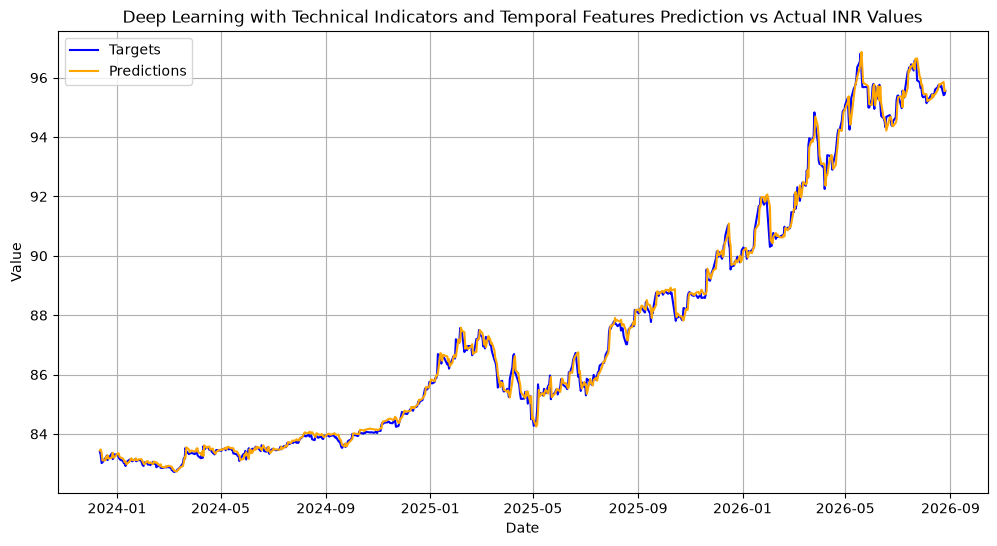

In [33]:
deep_temp_prediction_results = predict_and_store_log_return_model(
    model=model_dl_temp,
    model_name="Deep Learning with Technical Indicators and Temporal Features",
    train_inputs=X_train,
    test_inputs=X_test,
    train_targets=y_train,
    test_targets=y_test,
    train_current_prices=train_df_temp["INR"].values,
    test_current_prices=test_df_temp["INR"].values,
    target_scaler=target_scaler,
    model_results=model_results,
    output_path=RESULTS_PATH,
)

predicted_train_prices_temp = deep_temp_prediction_results["train_predictions"]
predicted_prices_temp = deep_temp_prediction_results["test_predictions"]
actual_train_prices_temp = deep_temp_prediction_results["train_actual_prices"]
actual_prices_temp = deep_temp_prediction_results["test_actual_prices"]
deep_temp_train_metrics = deep_temp_prediction_results["train_metrics"]
deep_temp_metrics = deep_temp_prediction_results["test_metrics"]

print(
    f"Test MAE: {deep_temp_metrics['mae']:.4f}, "
    f"Test MSE: {deep_temp_metrics['mse']:.4f}"
)
plot_predictions_vs_targets(
    predicted_prices_temp,
    actual_prices_temp,
    x_values=test_df_temp.index,
    title="Deep Learning with Technical Indicators and Temporal Features Prediction vs Actual INR Values",
)

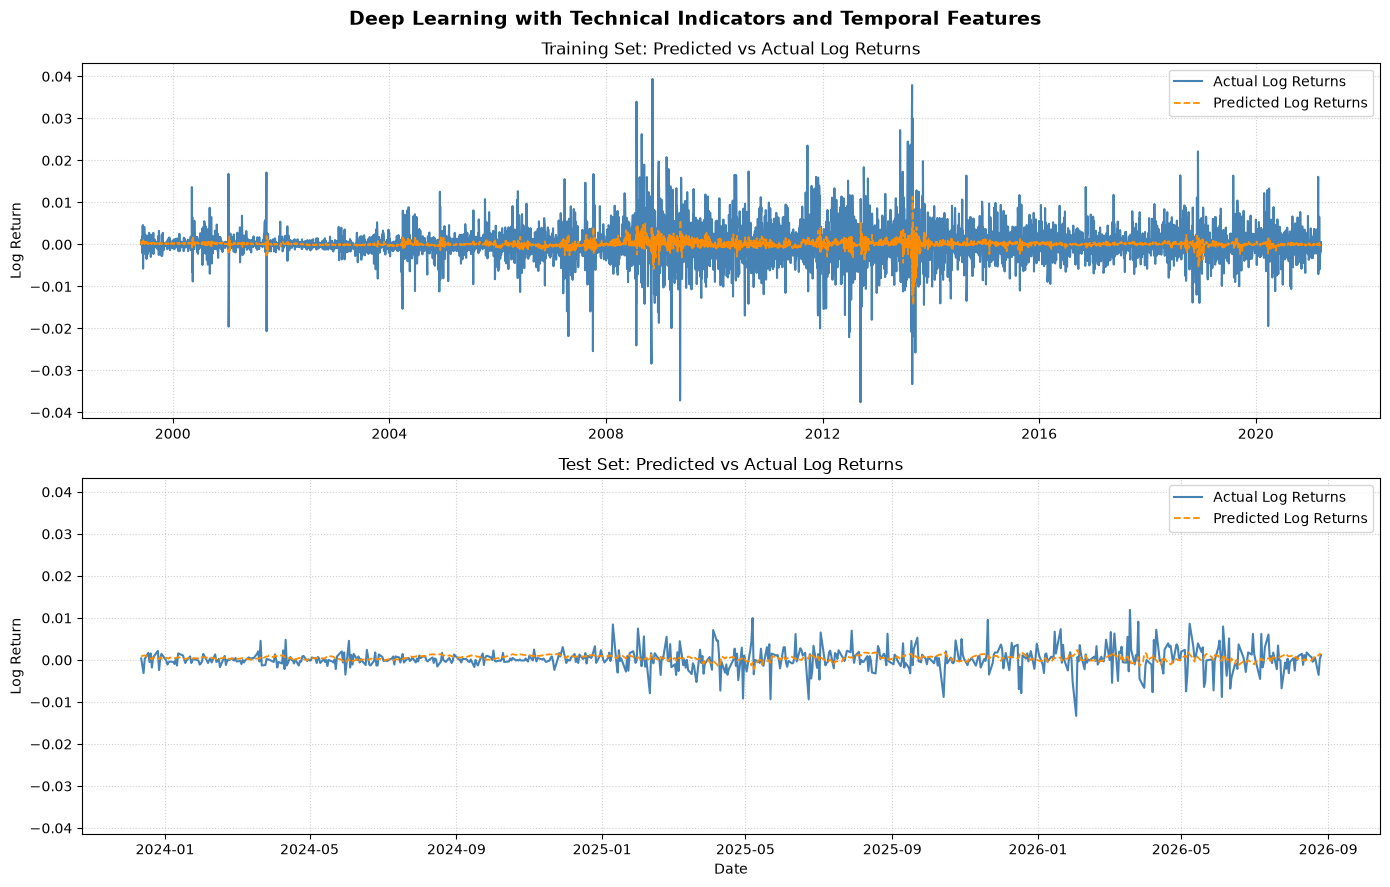

In [34]:
# PLOT PREDICTED LOG RETURNS vs ACTUAL LOG RETURNS
import matplotlib.pyplot as plt

predicted_train_log_returns = np.log(
    predicted_train_prices_temp / train_df_temp["INR"].to_numpy()
)
actual_train_log_returns = np.log(
    actual_train_prices_temp / train_df_temp["INR"].to_numpy()
)
predicted_test_log_returns = np.log(
    predicted_prices_temp / test_df_temp["INR"].to_numpy()
)
actual_test_log_returns = np.log(
    actual_prices_temp / test_df_temp["INR"].to_numpy()
)

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharey=True)

axes[0].plot(
    train_df_temp.index,
    actual_train_log_returns,
    label="Actual Log Returns",
    color="steelblue",
    linewidth=1.5,
)
axes[0].plot(
    train_df_temp.index,
    predicted_train_log_returns,
    label="Predicted Log Returns",
    color="darkorange",
    linestyle="--",
    linewidth=1.3,
)
axes[0].set_title("Training Set: Predicted vs Actual Log Returns")
axes[0].set_ylabel("Log Return")
axes[0].legend()
axes[0].grid(True, linestyle=":", alpha=0.6)

axes[1].plot(
    test_df_temp.index,
    actual_test_log_returns,
    label="Actual Log Returns",
    color="steelblue",
    linewidth=1.5,
)
axes[1].plot(
    test_df_temp.index,
    predicted_test_log_returns,
    label="Predicted Log Returns",
    color="darkorange",
    linestyle="--",
    linewidth=1.3,
)
axes[1].set_title("Test Set: Predicted vs Actual Log Returns")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Log Return")
axes[1].legend()
axes[1].grid(True, linestyle=":", alpha=0.6)

fig.suptitle(
    "Deep Learning with Technical Indicators and Temporal Features",
    fontsize=14,
    fontweight="bold",
)
fig.tight_layout()
plt.show()

## LSTM Model with Technical Indicators (Target: Log Returns + Directional Loss)

Financial log returns have a very low signal-to-noise ratio. A standard Mean Squared Error (MSE) loss causes the model to simply predict the mean (near zero) to minimize error, resulting in a flat-line prediction.

To fix this 'mean-seeking' behavior, we apply three fixes:
1. **Big-Move Aware Directional Loss**: Adds a heavy penalty when the predicted sign (Up/Down) doesn't match the actual sign, forcing the model to take a stance.
2. **Reduce Model Complexity**: Use 1 LSTM layer with 32 units to prevent the optimizer from getting stuck over-regularizing.
3. **Shorten Lookback Window**: Use 10 days instead of 30 to focus on recent price action rather than distant noise.

In [79]:
# ────────────────────────────────────────────────────────────────────────────
# Prepare technical-indicator data for the LSTM model
# ────────────────────────────────────────────────────────────────────────────
from utils import (
    create_time_series_dataloaders,
    train_torch_model_dataloader,
    predict_and_store_window_model,
    evaluate_torch_model_dataloader,
    plot_predictions_vs_targets,
)
import torch
import torch.nn as nn
import torch.optim as optim

lstm_df = calculate_technical_indicators(full_df, target_column=TARGET_COLUMN)
lstm_df["TARGET_LOG_RETURN_NEXT"] = lstm_df["Log_Returns"].shift(-1)
lstm_df = lstm_df.dropna()

LSTM_FEATURE_COLS = [
    TARGET_COLUMN,
    *FEATURE_COLUMNS,
    "MA_5", "MA_10", "MA_30", "MA_50", "MA_100",
    "EMA_5", "EMA_10", "EMA_30", "EMA_50", "EMA_100",
    "RSI",
    "BB_Middle", "BB_Upper", "BB_Lower",
    "Volatility",
    "ATR_14_proxy", "ATR_%_proxy",
    "Log_Returns",
]

LSTM_WINDOW_SIZE = 10     # Shorter window to focus on recent price action
LSTM_HIDDEN_SIZE = 32     # Smaller network to avoid mean-collapse
LSTM_NUM_LAYERS = 1
LSTM_DROPOUT = 0.0
LSTM_LR = 1e-3
LSTM_EPOCHS = 80
LSTM_BATCH_SIZE = 32
LSTM_PATIENCE = 10

print(f"LSTM dataframe shape: {lstm_df.shape}")


LSTM dataframe shape: (6805, 25)


In [80]:
# ────────────────────────────────────────────────────────────────────────────
# Create windowed dataloaders predicting Log Returns
# ────────────────────────────────────────────────────────────────────────────
lstm_loaders = create_time_series_dataloaders(
    data=lstm_df,
    target_column="TARGET_LOG_RETURN_NEXT",
    feature_columns=LSTM_FEATURE_COLS,
    window_size=LSTM_WINDOW_SIZE,
    offset=0,
    target_size=1,
    stride=1,
    batch_size=LSTM_BATCH_SIZE,
    train_fraction=TRAIN_FRACTION,
    validation_fraction=VALIDATION_FRACTION,
    scale_features=True,
    scale_targets=True,
    shuffle_train=True,
    device=DEVICE,
)
print(f"Train samples: {len(lstm_loaders['train_dataset'])}")


Train samples: 5434


In [81]:
# ────────────────────────────────────────────────────────────────────────────
# LSTM Model Definition
# ────────────────────────────────────────────────────────────────────────────
class LSTMForecaster(nn.Module):
    def __init__(self, input_size, hidden_size=32, num_layers=1, dropout=0.0, output_size=1):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True, dropout=dropout if num_layers > 1 else 0.0)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        lstm_out, (h_n, _) = self.lstm(x)
        last_hidden = h_n[-1]
        out = self.dropout(last_hidden)
        out = self.fc(out)
        return out.squeeze(-1)

lstm_model = LSTMForecaster(
    input_size=len(LSTM_FEATURE_COLS),
    hidden_size=LSTM_HIDDEN_SIZE,
    num_layers=LSTM_NUM_LAYERS,
    dropout=LSTM_DROPOUT,
).to(DEVICE)


In [82]:
# ────────────────────────────────────────────────────────────────────────────
# Custom Directional Loss & Training
# ────────────────────────────────────────────────────────────────────────────
class BigMoveAwareLoss(nn.Module):
    """
    Penalizes both directional mismatches AND missing large market moves.
    Explicitly targets moves >= 1.5 sigma for heavy penalization.
    """
    def __init__(self, dir_penalty=0.5, mag_penalty=2.0, sigma_threshold=1.5):
        super().__init__()
        self.mse = nn.MSELoss(reduction='none')
        self.dir_penalty = dir_penalty
        self.mag_penalty = mag_penalty
        self.sigma_threshold = sigma_threshold
        
    def forward(self, y_pred, y_true):
        sq_error = self.mse(y_pred, y_true)
        
        weight = 1.0 + self.mag_penalty * torch.abs(y_true)
        big_move_mask = (torch.abs(y_true) >= self.sigma_threshold).float()
        weight = weight + (big_move_mask * self.mag_penalty * 2.0)
        
        weighted_mse = sq_error * weight
        
        sign_mismatch = torch.relu(-torch.sign(y_pred) * torch.sign(y_true))
        dir_weight = torch.abs(y_true) + (big_move_mask * 2.0)
        dir_loss = sign_mismatch * dir_weight * self.dir_penalty
        
        return torch.mean(weighted_mse + dir_loss)

lstm_optimizer = optim.Adam(lstm_model.parameters(), lr=LSTM_LR, weight_decay=1e-5)
lstm_loss_fn = BigMoveAwareLoss(dir_penalty=0.5, mag_penalty=2.0, sigma_threshold=1.5)
lstm_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    lstm_optimizer, mode="min", factor=0.5, patience=4, verbose=True
)

lstm_history = train_torch_model_dataloader(
    model=lstm_model,
    optimizer=lstm_optimizer,
    loss_function=lstm_loss_fn,
    train_loader=lstm_loaders["train_loader"],
    val_loader=lstm_loaders["val_loader"],
    epochs=LSTM_EPOCHS,
    device=DEVICE,
    log_every=10,
    scheduler=lstm_scheduler,
    early_stopping_patience=LSTM_PATIENCE,
)


c:\Users\xprin\Desktop\AIML\.venv\Lib\site-packages\torch\optim\lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 10/80 - Train Loss: 9.3315, Val Loss: 2.1417
Early stopping triggered at epoch 13. Restoring best weights (Val Loss: 2.0914).


In [83]:
# ────────────────────────────────────────────────────────────────────────────
# Evaluate LSTM and store predictions (Log Returns scale)
# ────────────────────────────────────────────────────────────────────────────
lstm_eval_results = predict_and_store_window_model(
    model=lstm_model,
    model_name="LSTM + Tech Indicators (Directional)",
    loaders_dict=lstm_loaders,
    model_results=model_results,
    device=DEVICE,
    output_path=str(RESULTS_PATH),
    metadata={"window_size": LSTM_WINDOW_SIZE, "target": "Log_Returns"},
)

for split_name in ["train", "validation", "test"]:
    result = lstm_eval_results.get(split_name)
    if result is not None:
        m = result["metrics"]
        print(f"{split_name.capitalize():>12s} — MAE: {m['mae']:.5f}  RMSE: {m['rmse']:.5f}  Dir. Acc: {m['directional_accuracy']:.2f}%")


       Train — MAE: 0.00279  RMSE: 0.00434  Dir. Acc: 74.89%
  Validation — MAE: 0.00208  RMSE: 0.00283  Dir. Acc: 72.61%
        Test — MAE: 0.00178  RMSE: 0.00262  Dir. Acc: 68.68%


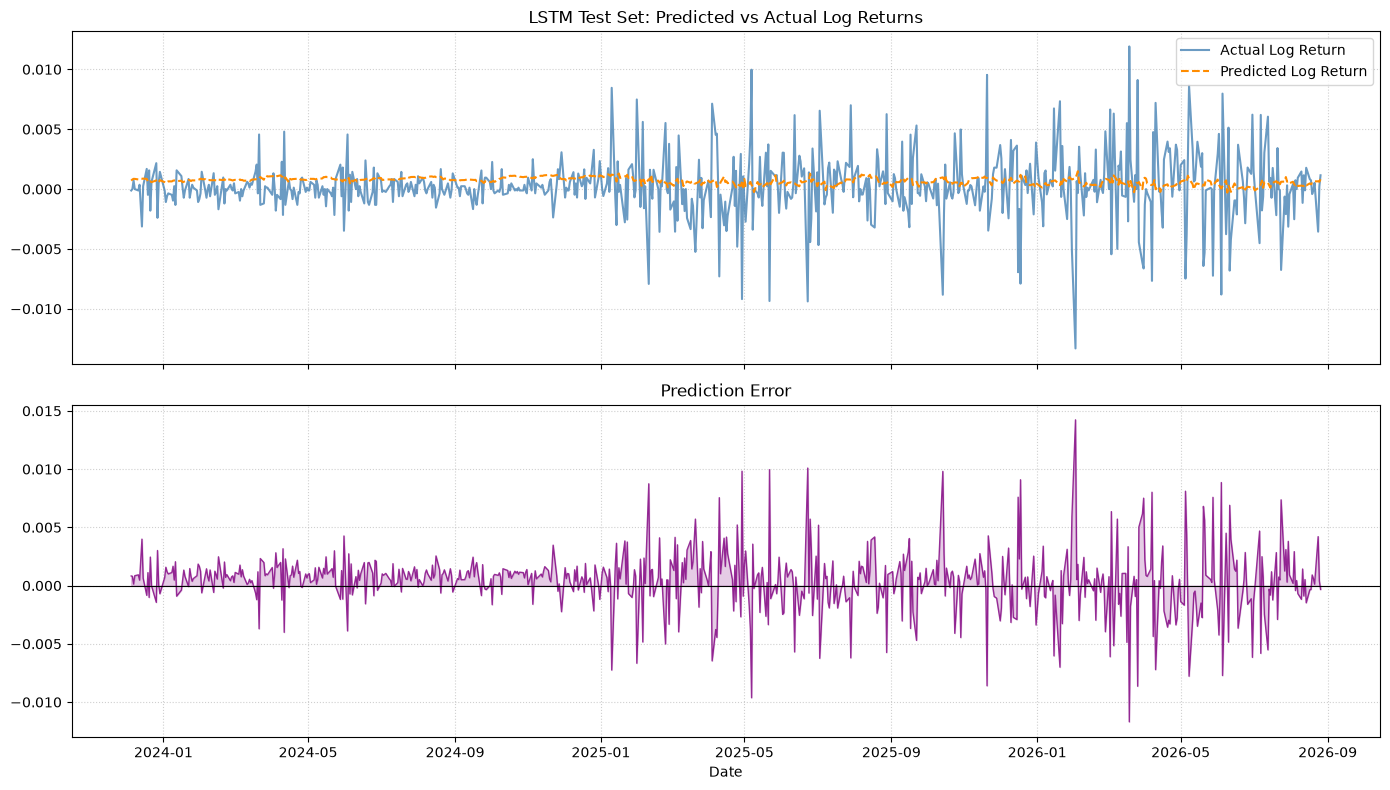

In [84]:
# ────────────────────────────────────────────────────────────────────────────
# Plot LSTM predictions vs actuals for Log Returns (Test set)
# ────────────────────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
test_result = lstm_eval_results["test"]

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
axes[0].plot(test_result["dates"], test_result["targets"], label="Actual Log Return", color="steelblue", alpha=0.8)
axes[0].plot(test_result["dates"], test_result["predictions"], label="Predicted Log Return", color="darkorange", linestyle="--", linewidth=1.5)
axes[0].set_title("LSTM Test Set: Predicted vs Actual Log Returns")
axes[0].legend()
axes[0].grid(True, linestyle=":", alpha=0.6)

errors = test_result["predictions"] - test_result["targets"]
# Use plot and fill_between instead of bar to avoid empty plots on datetime axes
axes[1].plot(test_result["dates"], errors, color="purple", linewidth=1.0, alpha=0.8)
axes[1].fill_between(test_result["dates"], 0, errors, color="purple", alpha=0.2)
axes[1].axhline(y=0, color="black", linewidth=0.8)
axes[1].set_title("Prediction Error")
axes[1].set_xlabel("Date")
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()


## EUR/USD LSTM Model (Target: Log Returns + Directional Loss)

Applying the exact same directional LSTM architecture to the EUR/USD exchange rate.
We calculate technical indicators centered on EUR as the target.

In [85]:
# ────────────────────────────────────────────────────────────────────────────
# Prepare technical-indicator data for EUR/USD
# ────────────────────────────────────────────────────────────────────────────

eur_df = calculate_technical_indicators(full_df, target_column="EUR")
eur_df["TARGET_LOG_RETURN_NEXT"] = eur_df["Log_Returns"].shift(-1)
eur_df = eur_df.dropna()

EUR_FEATURE_COLUMNS = ["INR", "JPY", "FFER", "US10YY"]
EUR_LSTM_FEATURE_COLS = [
    "EUR",
    *EUR_FEATURE_COLUMNS,
    "MA_5", "MA_10", "MA_30", "MA_50", "MA_100",
    "EMA_5", "EMA_10", "EMA_30", "EMA_50", "EMA_100",
    "RSI",
    "BB_Middle", "BB_Upper", "BB_Lower",
    "Volatility",
    "ATR_14_proxy", "ATR_%_proxy",
    "Log_Returns",
]

print(f"EUR LSTM dataframe shape: {eur_df.shape}")


EUR LSTM dataframe shape: (6805, 25)


In [86]:
# ────────────────────────────────────────────────────────────────────────────
# Create windowed dataloaders predicting EUR Log Returns
# ────────────────────────────────────────────────────────────────────────────
eur_lstm_loaders = create_time_series_dataloaders(
    data=eur_df,
    target_column="TARGET_LOG_RETURN_NEXT",
    feature_columns=EUR_LSTM_FEATURE_COLS,
    window_size=LSTM_WINDOW_SIZE,
    offset=0,
    target_size=1,
    stride=1,
    batch_size=LSTM_BATCH_SIZE,
    train_fraction=TRAIN_FRACTION,
    validation_fraction=VALIDATION_FRACTION,
    scale_features=True,
    scale_targets=True,
    shuffle_train=True,
    device=DEVICE,
)
print(f"Train samples: {len(eur_lstm_loaders['train_dataset'])}")


Train samples: 5434


In [87]:
# ────────────────────────────────────────────────────────────────────────────
# Initialize & Train EUR LSTM Model
# ────────────────────────────────────────────────────────────────────────────
eur_lstm_model = LSTMForecaster(
    input_size=len(EUR_LSTM_FEATURE_COLS),
    hidden_size=LSTM_HIDDEN_SIZE,
    num_layers=LSTM_NUM_LAYERS,
    dropout=LSTM_DROPOUT,
).to(DEVICE)

eur_lstm_optimizer = optim.Adam(eur_lstm_model.parameters(), lr=LSTM_LR, weight_decay=1e-5)
eur_lstm_loss_fn = BigMoveAwareLoss(dir_penalty=0.5, mag_penalty=2.0, sigma_threshold=1.5)
eur_lstm_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    eur_lstm_optimizer, mode="min", factor=0.5, patience=4, verbose=True
)

eur_lstm_history = train_torch_model_dataloader(
    model=eur_lstm_model,
    optimizer=eur_lstm_optimizer,
    loss_function=eur_lstm_loss_fn,
    train_loader=eur_lstm_loaders["train_loader"],
    val_loader=eur_lstm_loaders["val_loader"],
    epochs=LSTM_EPOCHS,
    device=DEVICE,
    log_every=10,
    scheduler=eur_lstm_scheduler,
    early_stopping_patience=LSTM_PATIENCE,
)


c:\Users\xprin\Desktop\AIML\.venv\Lib\site-packages\torch\optim\lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch 10/80 - Train Loss: 7.3804, Val Loss: 4.2799
Early stopping triggered at epoch 20. Restoring best weights (Val Loss: 4.2799).


In [88]:
# ────────────────────────────────────────────────────────────────────────────
# Evaluate EUR LSTM and store predictions
# ────────────────────────────────────────────────────────────────────────────
eur_lstm_eval_results = predict_and_store_window_model(
    model=eur_lstm_model,
    model_name="EUR LSTM + Tech Indicators (Directional)",
    loaders_dict=eur_lstm_loaders,
    model_results=model_results,
    device=DEVICE,
    output_path=str(RESULTS_PATH),
    metadata={"window_size": LSTM_WINDOW_SIZE, "target": "EUR_Log_Returns"},
)

for split_name in ["train", "validation", "test"]:
    result = eur_lstm_eval_results.get(split_name)
    if result is not None:
        m = result["metrics"]
        print(f"{split_name.capitalize():>12s} — MAE: {m['mae']:.5f}  RMSE: {m['rmse']:.5f}  Dir. Acc: {m['directional_accuracy']:.2f}%")


       Train — MAE: 0.00447  RMSE: 0.00599  Dir. Acc: 75.06%
  Validation — MAE: 0.00388  RMSE: 0.00512  Dir. Acc: 73.20%
        Test — MAE: 0.00309  RMSE: 0.00424  Dir. Acc: 75.88%


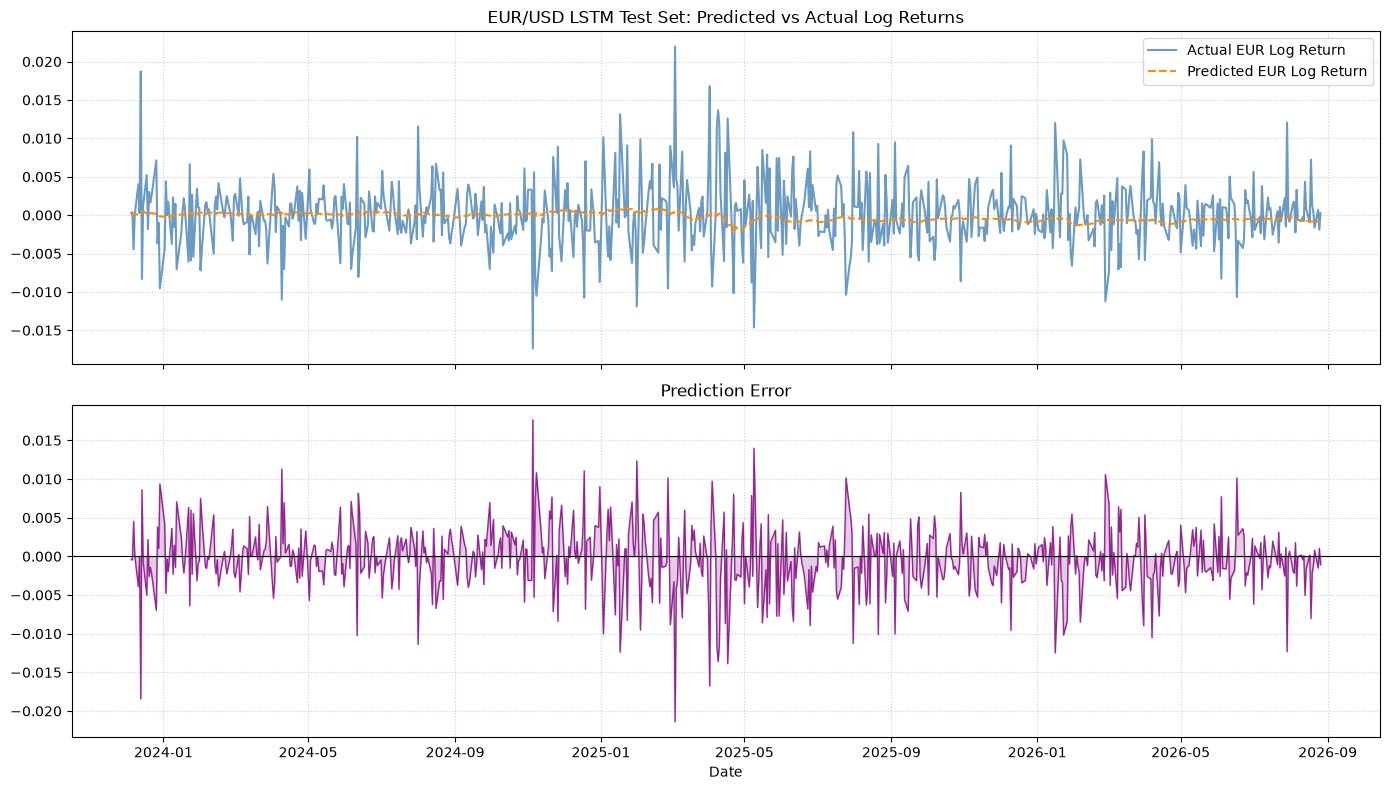

In [89]:
# ────────────────────────────────────────────────────────────────────────────
# Plot EUR LSTM predictions vs actuals (Test set)
# ────────────────────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
eur_test_result = eur_lstm_eval_results["test"]

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
axes[0].plot(eur_test_result["dates"], eur_test_result["targets"], label="Actual EUR Log Return", color="steelblue", alpha=0.8)
axes[0].plot(eur_test_result["dates"], eur_test_result["predictions"], label="Predicted EUR Log Return", color="darkorange", linestyle="--", linewidth=1.5)
axes[0].set_title("EUR/USD LSTM Test Set: Predicted vs Actual Log Returns")
axes[0].legend()
axes[0].grid(True, linestyle=":", alpha=0.6)

errors = eur_test_result["predictions"] - eur_test_result["targets"]
axes[1].plot(eur_test_result["dates"], errors, color="purple", linewidth=1.0, alpha=0.8)
axes[1].fill_between(eur_test_result["dates"], 0, errors, color="purple", alpha=0.2)
axes[1].axhline(y=0, color="black", linewidth=0.8)
axes[1].set_title("Prediction Error")
axes[1].set_xlabel("Date")
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()
